# Computer Vision Assignments: Sessions 1 & 2

This notebook contains tasks and assignments based on Sessions 1 and 2. You are required to implement the functions and complete the exercises as described. Use OpenCV and other necessary libraries like NumPy and Matplotlib.

**Instructions:**
- Complete each task in the provided code cells.
- Test your implementations with sample images (e.g., download test images [here](https://sipi.usc.edu/database/database.php?volume=misc) or [here](https://www.hlevkin.com/hlevkin/06testimages.htm) or use your own test images).
- Include comments in your code for clarity.
- Display results using cv2.imshow() or Matplotlib where appropriate.
- Submit the completed notebook along with any output images or explanations on [our google drive for the CV sessions](https://drive.google.com/drive/folders/1IjVhJmAXxNQTGT-ybJ-yc5smYtR5v8CO?usp=sharing) **upload your files in a new folder under your name**

## Session 1: Basic Image Operations (Reading, Resizing, Cropping, Rotating)

### Task 1: Read and Display an Image
Read an image from a file and display it in both BGR and grayscale formats. Handle errors if the image cannot be read.

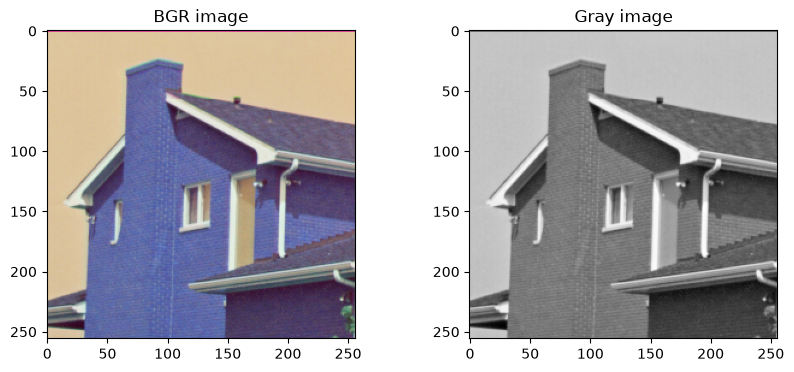

In [1]:
import cv2 as cv
import numpy as np
import sys
import matplotlib.pyplot as plt
%matplotlib inline

# Your code here
path = r"D:\SkyXperts-Vision-Course\tasks\test images\4.1.05.tiff"  # Replace with your image path

# Read in BGR
colored_img=cv.imread(path,cv.IMREAD_COLOR_BGR)

# Read in Grayscale
gray_img=cv.imread(path,0)

# Display both using cv.imshow() or plt.imshow()
#first i need to handle path errors 
assert colored_img is not None, "can't read image"
assert gray_img is not None, "can't read gray img"
#use cv.imshow()
cv.imshow("colored",colored_img)
cv.waitKey(0)
cv.imshow("gray",gray_img)
cv.waitKey(0)
cv.destroyAllWindows() 
#now i want to display them using matplot
plt.figure(figsize=(10, 4))
plt.subplot(1,2,1); plt.imshow(colored_img); plt.title("BGR image")
plt.subplot(1,2,2); plt.imshow(gray_img,cmap="gray"); plt.title("Gray image")
plt.show()

Matplotlib's default cmap is virdis this is why the gray is shown greenish in the plots so you have to set the cmap to gray to display it 

### Task 2: Resize Image with Aspect Ratio Preservation
Implement resizing while preserving aspect ratio. Downscale to 60% and upscale to 200%. Compare shapes and display originals vs resized.

In [2]:
# Your code here
# Load image
path= r"D:\SkyXperts-Vision-Course\tasks\test images\4.1.07.tiff"
img=cv.imread(path,1)
assert img is not None, "Can't read image"
# Downscale to 60%
#i will usefx and fy since they are more convenient 
scale_down= 0.6
scale_up= 2
down_img=cv.resize(img,None,fx=scale_down, fy=scale_down, interpolation=cv.INTER_AREA) 
# Upscale to 200%
up_img=cv.resize(img,None,fx=scale_up,fy=scale_up,interpolation=cv.INTER_CUBIC)

# Display all three
# plt.figure(figsize=(12, 4))
# plt.subplot(1,3,1); plt.imshow(img); plt.title("Original")
# plt.subplot(1,3,2); plt.imshow(down_img); plt.title("downsized image, Inter linear")
# plt.subplot(1,3,3); plt.imshow(up_img); plt.title("up_image, Inter cubic")
# plt.show()
cv.imshow("og",img)
cv.waitKey(0)
cv.imshow("downscaled", down_img)
cv.waitKey(0)
cv.imshow("upscaled", up_img)
cv.waitKey(0)
cv.destroyAllWindows()
#the upscaled image is a bit blurred 

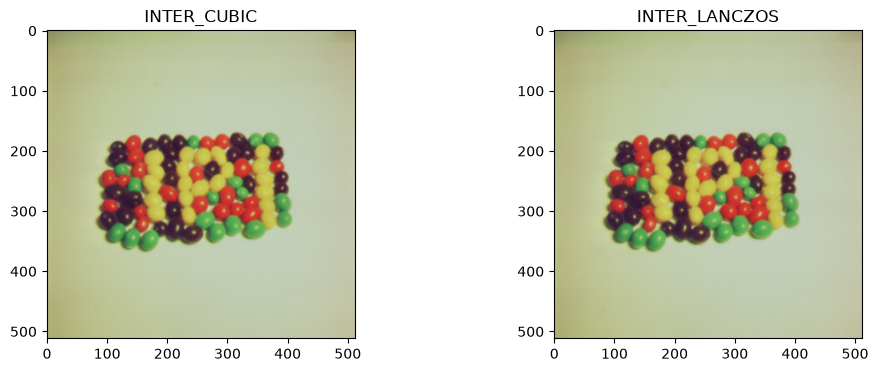

In [3]:
rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
plt.figure(figsize=(12, 4))
up_cubic=cv.resize(rgb_img,None,fx=scale_up,fy=scale_up,interpolation=cv.INTER_CUBIC)
up_lanczo=cv.resize(rgb_img,None,fx=scale_up,fy=scale_up,interpolation=cv.INTER_LANCZOS4)
plt.subplot(1,2,1); plt.imshow(up_cubic); plt.title("INTER_CUBIC")
plt.subplot(1,2,2); plt.imshow(up_lanczo); plt.title("INTER_LANCZOS")
plt.show()
#interlanczos is the best option for upscaling
#also notice how the colors change because of the different order of channels 

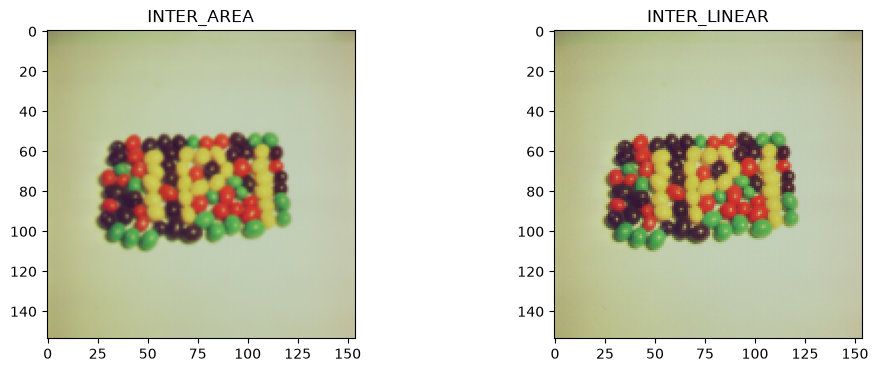

In [4]:
plt.figure(figsize=(12, 4))
down_area=cv.resize(rgb_img,None,fx=scale_down,fy=scale_down,interpolation=cv.INTER_AREA)
down_linear=cv.resize(rgb_img,None,fx=scale_down,fy=scale_down,interpolation=cv.INTER_LINEAR)
plt.subplot(1,2,1); plt.imshow(down_area); plt.title("INTER_AREA")
plt.subplot(1,2,2); plt.imshow(down_linear); plt.title("INTER_LINEAR")
plt.show()
#inter area is the only non pixelated img when downscaled buttt it is still blurred 
#also notice how the colors change because of the different order of channels 

### Task 3: Resize Without Preserving Aspect Ratio
Resize only width to 100 pixels, only height to 200 pixels, and both to (200, 200). Display and discuss distortions.

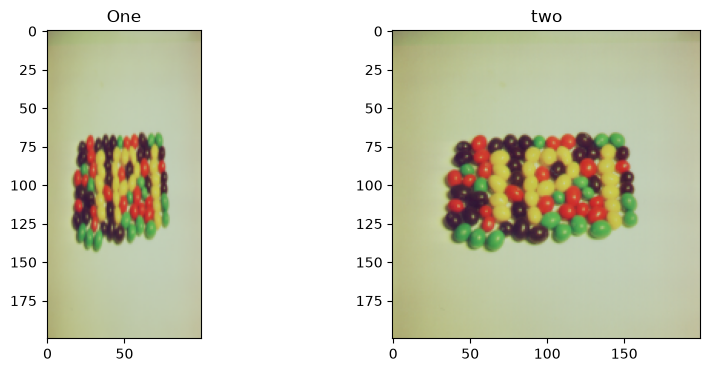

In [5]:
# Your code here
w=100
h=200
dim=(w,h)
resized_img=cv.resize(rgb_img,dim,interpolation=cv.INTER_AREA)
resized2=cv.resize(rgb_img,(200,200),interpolation=cv.INTER_LANCZOS4)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.imshow(resized_img); plt.title("One")
plt.subplot(1,2,2); plt.imshow(resized2); plt.title("two")
plt.show()

the first img got squished horizontally 
the second one looks fine 

### Task 4: Resize Using Scale Factors (fx, fy)
Scale up by 1.2 in both directions and down by 0.6. Use different interpolations (INTER_LINEAR, INTER_NEAREST) and compare quality.

In [ ]:
# Your code here
# Experiment with interpolations

I have already used scale factors above and compared interpolation methods 
between both Linear and Nearest , linear is better because it takes the average 4 pixels around the center pixel for interpolation while Nearest takes only the closest pixel which may explain why it looks laggy 

### Task 5: Cropping an Image
Crop a region (e.g., [20:200, 50:200]) from the image. Display original and cropped.

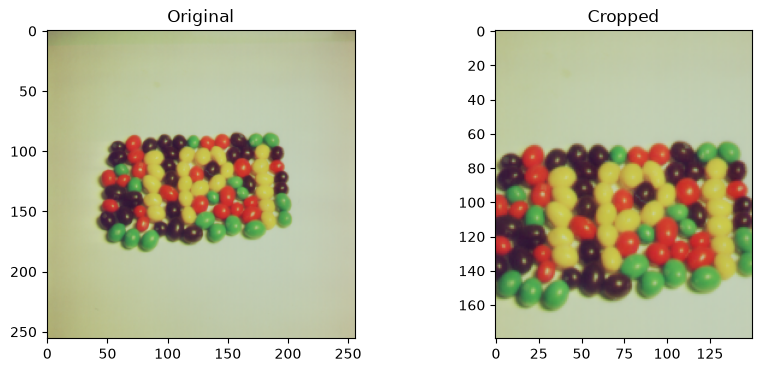

In [6]:
# Your code here
#images are generally cropped using slicing 
cropped=rgb_img[20:200, 50:200]
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.imshow(rgb_img); plt.title("Original")
plt.subplot(1,2,2); plt.imshow(cropped); plt.title("Cropped")
plt.show()

### Task 6: Advanced Cropping - Patch Image into Blocks
Divide the image into 4 equal blocks (2x2 grid) by cropping. Display each block separately and then stitch them back using NumPy concatenation to verify.

(256, 256, 3)


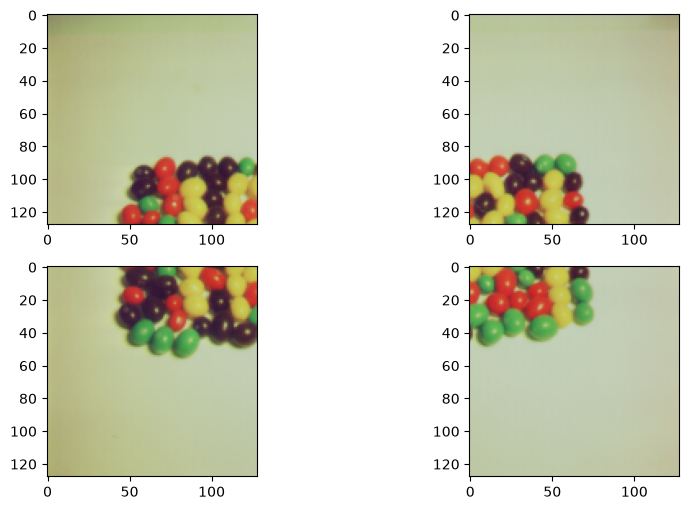

False


In [7]:
# Your code here
# Calculate midpoints for height and width >>i think this means quarters
#e3rafi el dimensions bta3et el img el awl 
print(rgb_img.shape)
north_west=rgb_img[0:128, 0:128]
south_west=rgb_img[128:256, 0:128]
north_east=rgb_img[0:128, 128:256]
south_east=rgb_img[128:256, 128:256]
#mashi el confusion hna eni ba slice el y el awl msh el x 

# Crop into top-left, top-right, bottom-left, bottom-right

# Display each
plt.figure(figsize=(10,6))
plt.subplot(2,2,1); plt.imshow(north_west)
plt.subplot(2,2,2); plt.imshow(north_east);
plt.subplot(2,2,3); plt.imshow(south_west);
plt.subplot(2,2,4); plt.imshow(south_east)
plt.show()
# Stitch back (use np.hstack and np.vstack)
top=np.hstack([north_west, north_east])  
bottom= np.hstack([south_west, south_east])
stitched=np.vstack([top, bottom])
#aw mmkn t3kesi  
stitched=cv.cvtColor(stitched,cv.COLOR_RGB2BGR)      
print(np.array_equal(stitched, rgb_img))   
cv.imshow("stitched", stitched)
cv.waitKey(0)
cv.destroyAllWindows()

### Task 7: Rotating an Image
Rotate the image by 45°, 90°, and 180° using getRotationMatrix2D and warpAffine. Display all rotations.

In [8]:
# Your code here
# Calculate center >> exactly the midpoint of each y and x
center=(128,128)
# For each angle: get matrix, warp, display
M=cv.getRotationMatrix2D(center=center,angle=45,scale=1) 
img_45=cv.warpAffine(src=img,M=M,dsize=(256,256), borderMode=cv.BORDER_REPLICATE)
cv.imshow("45 degrees rotation",img_45)
cv.waitKey(0)
cv.destroyAllWindows() #the corners are black 3shan ana masta5demtesh border modes 
#border replicate expands the edge pixels
M=cv.getRotationMatrix2D(center=center,angle=90,scale=1) 
img_90=cv.warpAffine(src=img,M=M,dsize=(256,256), borderMode=cv.BORDER_WRAP)
cv.imshow("90 degrees rotation",img_90)
cv.waitKey(0)
cv.destroyAllWindows()
M=cv.getRotationMatrix2D(center=center,angle=180,scale=1) 
img_180=cv.warpAffine(src=img,M=M,dsize=(256,256), borderMode=cv.BORDER_REFLECT)
cv.imshow("180 degrees rotation",img_180)
cv.waitKey(0)
cv.destroyAllWindows()


### Task 8: Rotate with Scaling
Rotate by 45° and scale by 0.5 in **one** operation. Compare with separate resize and rotate.

In [10]:
# Your code here
M=cv.getRotationMatrix2D(center=center,angle=45,scale=0.5) 
scaled_rotated=cv.warpAffine(src=img,M=M,dsize=(256,256))
cv.imshow("90 degrees rotation",scaled_rotated)
cv.waitKey(0)
just_rotated=cv.getRotationMatrix2D(center=center,angle=45,scale=1)
just_scaled=cv.resize(img,None,fx=0.5,fy=0.5,interpolation=cv.INTER_AREA)
cv.imshow("only rotated", just_rotated)
cv.waitKey(0)
cv.imshow("only resized", just_scaled)
cv.waitKey(0)
cv.destroyAllWindows() 

## Session 2: Image Acquisition, Formats, Color Spaces, Enhancement, and Filtering

### Task 9: Read Image in Different Color Spaces
Read an image in BGR, convert to RGB (for Matplotlib), HSV, LAB and Grayscale. Display all.

In [11]:
# Your code here
# Use cv.cvtColor()
path=r"D:\SkyXperts-Vision-Course\tasks\test images\4.1.05.tiff"
img=cv.imread(path,cv.IMREAD_COLOR_BGR)
rgb_img=cv.cvtColor(img,cv.COLOR_BGR2RGB)
hsv_img=cv.cvtColor(img,cv.COLOR_BGR2HSV)
lab_img=cv.cvtColor(img,cv.COLOR_BGR2LAB)
gray_img=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
cv.imshow("Original",img)
cv.waitKey(0)
cv.imshow("RGB",rgb_img)
cv.waitKey(0)
cv.imshow("HSV",hsv_img)
cv.waitKey(0)
cv.imshow("lab",lab_img)
cv.waitKey(0)
cv.imshow("gray",gray_img)
cv.waitKey(0)
cv.destroyAllWindows()

### Task 10: Image Sharpening
Apply cv2.blur() with a 5x5 kernel, then use cv2.filter2D() with sharpening kernels of varying strengths (e.g., [[0, -1, 0], [-1, 5, -1], [0, -1, 0]] and [[0, -2, 0], [-2, 9, -2], [0, -2, 0]]).
Compare between original and sharpened image after blurring.

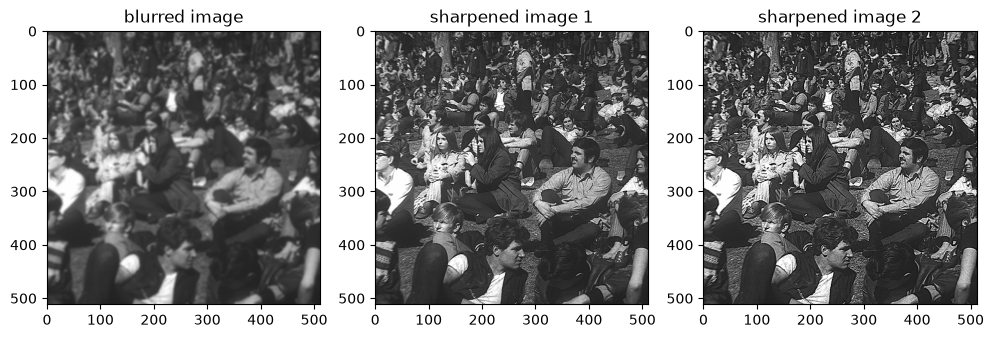

In [12]:
# Your code here
path=r"D:\SkyXperts-Vision-Course\tasks\test images\crowd.pgm"
img=cv.imread(path,1)
# Use cv2.blur
blurred=cv.blur(img,(5,5))
sharpening_filter=[
    [0,-1,0],
    [-1,5,-1],
    [0,-1,0]
]
sharpening_filter1=[
    [0,-2,0],
    [-2,9,-2],
    [0,-2,0]
]
sharpened0 = cv.filter2D(img, ddepth=-1, kernel=np.asarray(sharpening_filter, dtype=np.float32))
sharpened1 = cv.filter2D(
    img,
    ddepth=-1,
    kernel=np.asarray(sharpening_filter1, dtype=np.float32)
)
#cv.filter2D needs a numpy array 
plt.figure(figsize=(12,6))
plt.subplot(1,3,1); plt.imshow(blurred); plt.title("blurred image")
plt.subplot(1,3,2); plt.imshow(sharpened0); plt.title("sharpened image 1")
plt.subplot(1,3,3); plt.imshow(sharpened1); plt.title("sharpened image 2")
plt.show()
# Define sharpen kernel, use cv.filter2D()

### Task 11: Add Salt and Pepper Noise to Image
Implement a function to add salt and pepper noise to an image. Control noise density (e.g., 0.05).

In [13]:
# Your code here
def add_salt_pepper_noise(image, density=0.05):
    # Implement using random pixels set to 0 or 255
    noisy = image.copy()              
    H, W = image.shape[:2]
    # one random number per pixel position
    r = np.random.rand(H, W)
    noisy[r < density / 2] = 0                
    noisy[r > 1 - density / 2] = 255      
    return noisy

# Apply to an image and display
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
noisy_img = add_salt_pepper_noise(gray)
cv.imshow("original", img)
cv.waitKey(0)
cv.imshow("image with salt and pepper noise", noisy_img)
cv.waitKey(0)
cv.destroyAllWindows()
#the white noise is too btight ha2alel el brightness shwaia 
#still looks weird 

### Task 12: Remove Salt and Pepper Noise Using Median Filter
Apply cv.medianBlur() to a noisy image. Experiment with kernel sizes (3,5,7) and compare results.

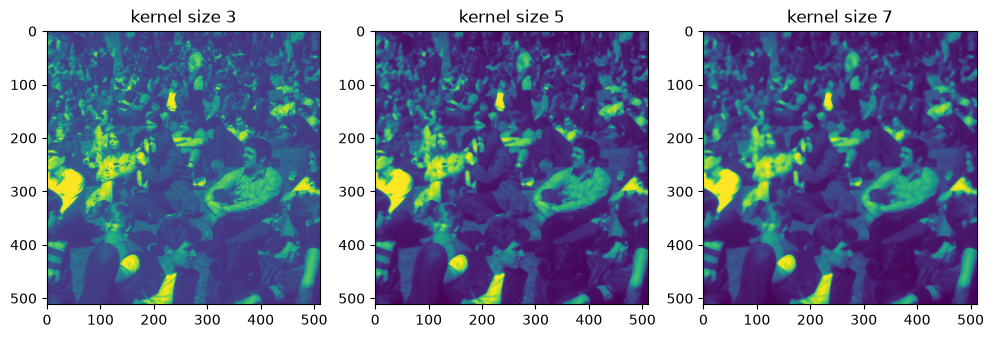

In [14]:
# Your code here
noisy = noisy_img
#noisy=cv.cvtColor(noisy_img,cv.COLOR_GRAY2RGB)
median_blur=cv.medianBlur(noisy,3)
median_blur1=cv.medianBlur(noisy,5)
median_blur2=cv.medianBlur(noisy,7)
plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(median_blur); plt.title("kernel size 3")
plt.subplot(1,3,2); plt.imshow(median_blur1); plt.title("kernel size 5")
plt.subplot(1,3,3); plt.imshow(median_blur2); plt.title("kernel size 7")
plt.show()

kernel size 3 is best here because it removed the noise without applying too much blur or smoothing too much of the image but it did not eliminate the noise 100%

### Task 13: Implement Adaptive Median Filter
Write a custom function for adaptive median filtering. It should dynamically increase window size until noise is removed or max size is reached. Apply to a noisy image and compare with standard median.

In [15]:
# Your code here
def adaptive_median_filter(image, max_size=7):
    # Implement logic: for each pixel, start with small window, increase if needed
    H, W = image.shape[:2]                      
    pad = max_size // 2 #round down 
    padded = np.pad(image, pad, mode="reflect")   
    out = image.copy()

    for y in range(H):
        for x in range(W):
            cy, cx = y + pad, x + pad        # pixel position in the padded image
            size = 3

            while True:
                r = size // 2
                win = padded[cy-r:cy+r+1, cx-r:cx+r+1]
                zmin, zmax = win.min(), win.max()
                zmed = np.median(win)

                if zmin < zmed < zmax:                    # Stage A: median is trustworthy
                    zxy = padded[cy, cx]
                    out[y, x] = zxy if zmin < zxy < zmax else zmed   # Stage B
                    break

                size += 2                                 # median looks like noise: widen
                if size > max_size:                       # out of room: settle for the median
                    out[y, x] = zmed
                    break

    return out
#lazem to convert the img into grayscale first
def adaptive_median_filter(image, max_size=7):
    if image.ndim == 3:
        image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

    if max_size < 3 or max_size % 2 == 0:
        raise ValueError("max_size must be an odd integer of at least 3")

    H, W = image.shape
    pad = max_size // 2
    padded = np.pad(image, pad, mode="reflect")
    out = image.copy()

    for y in range(H):
        for x in range(W):
            cy, cx = y + pad, x + pad
            size = 3

            while True:
                r = size // 2
                win = padded[cy-r:cy+r+1, cx-r:cx+r+1]
                zmin, zmax = win.min(), win.max()
                zmed = np.median(win)

                if zmin < zmed < zmax:
                    zxy = padded[cy, cx]
                    out[y, x] = zxy if zmin < zxy < zmax else zmed
                    break

                if size >= max_size:
                    out[y, x] = zmed
                    break

                size += 2

    return out


noisy_gray = (
    cv.cvtColor(noisy_img, cv.COLOR_BGR2GRAY)
    if noisy_img.ndim == 3
    else noisy_img
)
adaptively_blurred = adaptive_median_filter(noisy_gray)
median_reference = cv.medianBlur(noisy_gray, 3)

cv.imshow("regular 3x3 median filter", median_reference)
cv.waitKey(0)
cv.imshow("adaptively filtered image", adaptively_blurred)
cv.waitKey(0)
cv.destroyAllWindows()
cv.imshow("regular 3*3 median filter", median_blur)
cv.waitKey(0)
cv.imshow("adaptively blurred image", adaptively_blurred)
cv.waitKey(0)
cv.destroyAllWindows()

# Test on noisy image

### Task 14: Implement Bilateral Filter Function
Write a Python function to perform bilateral filtering on an image. Use Gaussian weights for both spatial and intensity. Parameters: diameter, sigma_color, sigma_space. Compare with cv.bilateralFilter().

In [ ]:
# Your code here
def custom_bilateral_filter(image, diameter, sigma_color, sigma_space):
    # Implement using nested loops or vectorized (efficiently)
    # For each pixel, compute weighted sum based on distance and intensity diff
    r = diameter // 2
    padded = np.pad(image, r, mode="reflect").astype(np.float64)
    out = np.zeros_like(image, dtype=np.float64)
    # spatial weights depend only on offsets, so compute them ONCE
    ax = np.arange(-r, r + 1)
    xx, yy = np.meshgrid(ax, ax)
    spatial = np.exp(-(xx**2 + yy**2) / (2 * sigma_space**2))

    for y in range(image.shape[0]):
        for x in range(image.shape[1]):
            win = padded[y:y+diameter, x:x+diameter]
            center = padded[y + r, x + r]
            intensity = np.exp(-(win - center)**2 / (2 * sigma_color**2))
            w = spatial * intensity
            out[y, x] = np.sum(w * win) / np.sum(w)

    return out.astype(np.uint8)
# Apply to image, display, and compare with OpenCV's version
path=r"D:\SkyXperts-Vision-Course\tasks\test images\7.2.01.tiff"
img=cv.imread(path,1)
# Fix: handle multichannel images (BGR/RGB) and compute weights per channel
def custom_bilateral_filter(image, diameter, sigma_color, sigma_space):
    if image.ndim == 3 and image.shape[2] == 3:
        out = np.zeros_like(image, dtype=np.float64)
        for c in range(image.shape[2]):
            out[:, :, c] = custom_bilateral_filter(image[:, :, c], diameter, sigma_color, sigma_space)
        return out.astype(np.uint8)

    r = diameter // 2
    padded = np.pad(image.astype(np.float64), ((r, r), (r, r)), mode="reflect")
    out = np.zeros_like(image, dtype=np.float64)

    yy, xx = np.meshgrid(np.arange(-r, r + 1), np.arange(-r, r + 1), indexing="ij")
    spatial = np.exp(-(xx**2 + yy**2) / (2 * sigma_space**2))

    for y in range(image.shape[0]):
        for x in range(image.shape[1]):
            win = padded[y:y + diameter, x:x + diameter]
            center = float(image[y, x])
            intensity = np.exp(-((win - center) ** 2) / (2 * sigma_color**2))
            weights = spatial * intensity
            denom = weights.sum()
            if denom == 0:
                out[y, x] = float(win.mean())
            else:
                out[y, x] = np.sum(weights * win) / denom

    return out.astype(np.uint8)

manual_bi = custom_bilateral_filter(img, 7, 30, 7)
builtin_bi=cv.bilateralFilter(img,7,3,3)
cv.imshow("Custom filter", manual_bi)
cv.waitKey(0)
cv.imshow("built in fileter", builtin_bi)
cv.waitKey(0)
cv.destroyAllWindows()

ValueError: operands could not be broadcast together with shapes (7,7) (7,7,9) 

### [BONUS] Task 15: Comprehensive Camera Task 
Combine: Live camera feed -> grayscale -> add noise -> remove with median -> sharpen. Display all stages in separate windows.

In [ ]:
# To read video from camera example:

camera_id = 0
delay = 30
window_name = 'frame'

cap = cv.VideoCapture(camera_id)

if not cap.isOpened():
    sys.exit()

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    #how to flip the frame horizontally 
    flipped_frame=cv.flip(frame,1)
    gray_frame=cv.cvtColor(flipped_frame,cv.COLOR_BGR2GRAY)
    noisy_frame=add_salt_pepper_noise(gray_frame)
    #frame=adaptive_median_filter(frame) #adaptive median filter slows down the video too much 
    #hagarab a apply the regular median filter 
    noiseless_frame=cv.medianBlur(noisy_frame,3)
    sharpened_frame = cv.filter2D(
    noiseless_frame,
    ddepth=-1,
    kernel=np.asarray(sharpening_filter, dtype=np.float32)
)
    #frame=cv.cvtColor(frame,cv.COLOR_GRAY2BGR)
    cv.imshow("raw frame", frame)
    cv.imshow("flipped frame", flipped_frame)
    cv.imshow("gray flipped frame", gray_frame)
    cv.imshow("salt and pepper noise", noisy_frame)
    cv.imshow("noiseless frame", noiseless_frame)
    cv.imshow("sharpened frame", sharpened_frame)

    if cv.waitKey(delay) & 0xFF == ord('q'):
        break

cap.release()
cv.destroyAllWindows()


# Your code here

### [BONUS]Task 16: Comprehensive Video Task
Similar to Task 18 but for a video file. Save the final processed video.

In [ ]:
# To read video from camera example:

camera_id = 0
delay = 30
window_name = 'frame'

cap = cv.VideoCapture(camera_id)

if not cap.isOpened():
    sys.exit()
fourcc = cv.VideoWriter_fourcc(*"mp4v")
out = cv.VideoWriter("output.mp4", fourcc, 30, (640, 480),isColor=False)
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    #how to flip the frame horizontally 
    flipped_frame=cv.flip(frame,1)
    gray_frame=cv.cvtColor(flipped_frame,cv.COLOR_BGR2GRAY)
    noisy_frame=add_salt_pepper_noise(gray_frame)
    #frame=adaptive_median_filter(frame) #adaptive median filter slows down the video too much 
    #hagarab a apply the regular median filter 
    noiseless_frame=cv.medianBlur(noisy_frame,3)
    sharpened_frame = cv.filter2D(
    noiseless_frame,
    ddepth=-1,
    kernel=np.asarray(sharpening_filter, dtype=np.float32)
)   
    out.write(sharpened_frame)
    #frame=cv.cvtColor(frame,cv.COLOR_GRAY2BGR)
    cv.imshow("sharpened frame", sharpened_frame)

    if cv.waitKey(delay) & 0xFF == ord('q'):
        break

cap.release()
out.release()
cv.destroyAllWindows()


# Your code here# Your code here



### Task 17: Performance Comparison
Time the execution of standard median vs adaptive median on a large noisy image. Discuss when adaptive median filter is better.

In [ ]:
import time
# Your code here
# Use time.time() to measure
import cv2 as cv
import numpy as np

# a large noisy image (grayscale)
img = cv.imread(r"D:\SkyXperts-Vision-Course\tasks\test images\7.2.01.tiff", cv.IMREAD_GRAYSCALE)
noisy = add_salt_pepper_noise(img, density=0.3)

# standard median
t0 = time.time()
std = cv.medianBlur(noisy, 3)
t_std = time.time() - t0

# adaptive median
t0 = time.time()
adapt = adaptive_median_filter(noisy, max_size=7)
t_adapt = time.time() - t0

print(f"Standard median: {t_std:.4f} s")
print(f"Adaptive median: {t_adapt:.4f} s")
print(f"Adaptive is {t_adapt / t_std:.0f}x slower")
print(f"PSNR standard: {cv.PSNR(img, std):.1f} dB | adaptive: {cv.PSNR(img, adapt):.1f} dB")


Standard median: 0.0006 s
Adaptive median: 14.8520 s
Adaptive is 23996x slower
PSNR standard: 22.9 dB | adaptive: 35.3 dB
